# Homework 2: Microelectrode Recording Detection
## Name: Jon Knapp
### Date: October 13, 2026
### Class: EE 522 Discrete Time Processing

### Problem 1: Time-domain plot of the original signal

To ensure the .wav file in the Canvas Homework folder is the same as the .wav file seen in the homework assignment, code will be generated to allow me to listen to the file.

In [28]:
import numpy as np
import soundfile as sf
from IPython.display import Audio

# --- Load the recording ---
filename = "Henderson2.wav"
x, fs = sf.read(filename)           # x: samples, fs: sampling rate (Hz)

# If the file is stereo, keep just the first channel
if x.ndim > 1:
    x = x[:, 0]

print(f"Sampling rate: {fs} Hz")
print(f"Samples: {len(x)}  |  Duration: {len(x)/fs:.2f} s")

# --- Play it ---
# Normalize to avoid clipping; the raw amplitude may be very small
x_play = x / np.max(np.abs(x))

Audio(x_play, rate=fs)

Sampling rate: 10000 Hz
Samples: 198540  |  Duration: 19.85 s


Fs = 10000 Hz | Samples = 198540 | Duration = 19.85 s


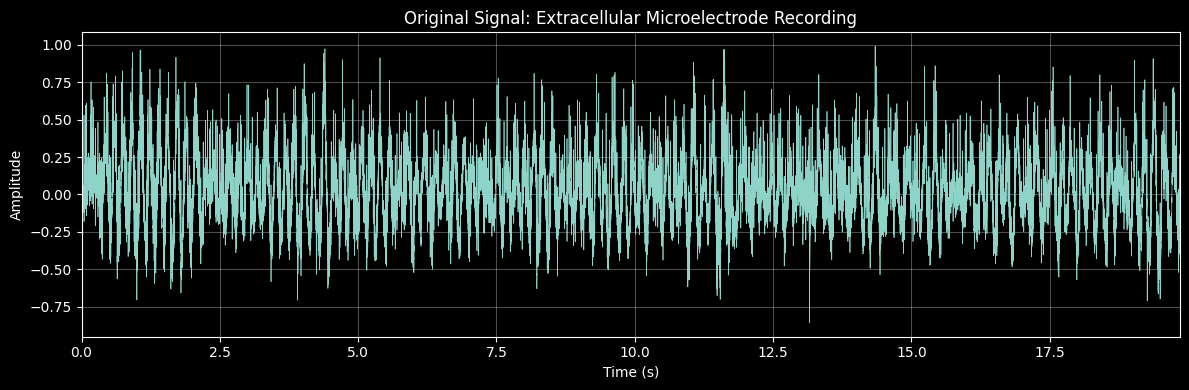

In [29]:
import matplotlib.pyplot as plt

N = len(x)
t = np.arange(N) / fs               # time vector in seconds

print(f"Fs = {fs} Hz | Samples = {N} | Duration = {N/fs:.2f} s")

# --- Deliverable 1: time-domain plot of the original signal ---
plt.figure(figsize=(12, 4))
plt.plot(t, x, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Original Signal: Extracellular Microelectrode Recording")
plt.xlim(t[0], t[-1])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p1_original_signal.png", dpi=200)
plt.show()

### Problem 2: Time-domain plot of the filtered signal

To help with filter design, the power spectrum of the raw signal is generated to help determine where exactly the low-pass filter should be applied (the cutoff).


Frequency resolution: 0.61 Hz


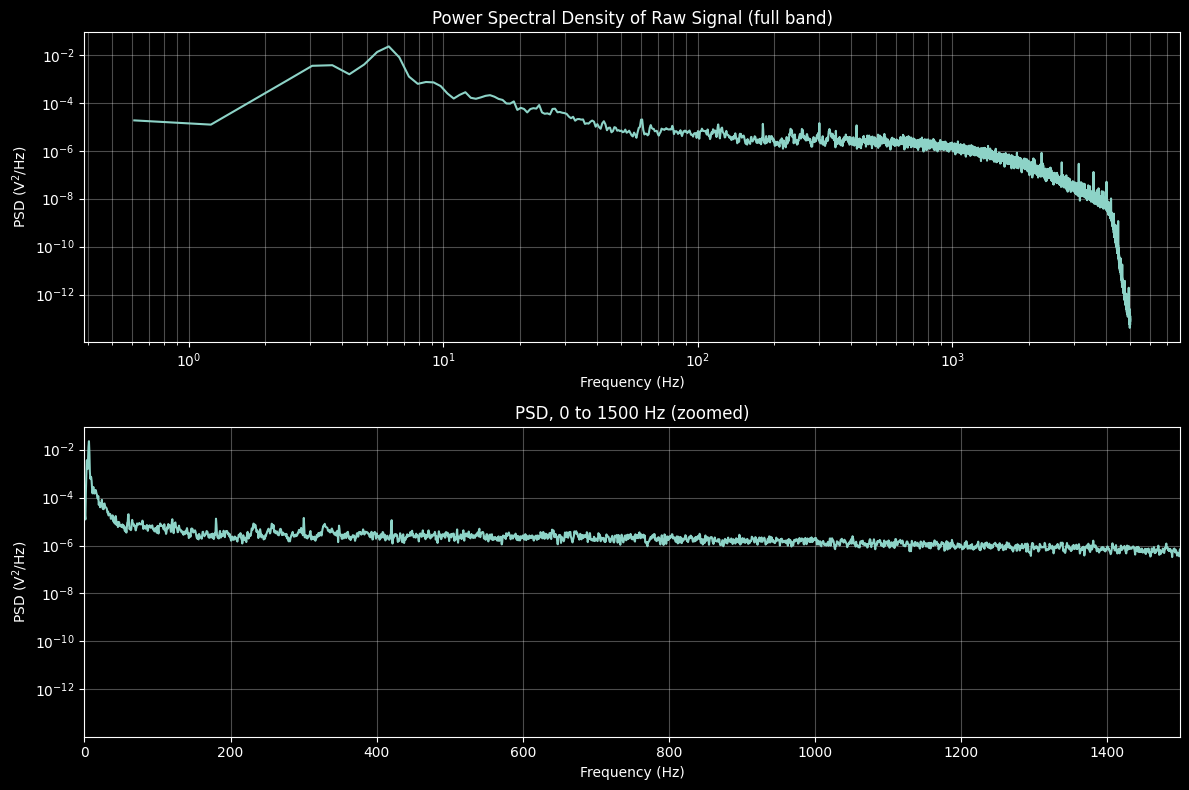

In [30]:
from scipy.signal import welch

# --- Power spectral density (Welch's method) ---
nperseg = 2**14                      # longer segment -> finer frequency resolution
f, Pxx = welch(x, fs=fs, nperseg=nperseg, noverlap=nperseg//2, window="hann")

print(f"Frequency resolution: {f[1] - f[0]:.2f} Hz")

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Full band, log-log: shows the overall shape of trend vs. noise floor vs. spike band
axes[0].loglog(f[1:], Pxx[1:])       # skip the DC bin for the log axis
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD (V$^2$/Hz)")
axes[0].set_title("Power Spectral Density of Raw Signal (full band)")
axes[0].grid(True, which="both", alpha=0.3)

# Zoom on low frequencies, log power: shows where the slow trend ends
axes[1].semilogy(f, Pxx)
axes[1].set_xlim(0, 1500)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("PSD (V$^2$/Hz)")
axes[1].set_title("PSD, 0 to 1500 Hz (zoomed)")
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.savefig("p2_power_spectrum.png", dpi=200)
plt.show()

What is seen:
* Large peak at 6 Hz. This is the low-frequency trend to remove.
* Spikes at 60 Hz, 180 Hz, 300 Hz, and 420 Hz. This could be power-line noise (60 Hz in the US with odd harmonics).
* Plateau seen from 100 Hz to 1 kHz, other than the spikes discussed above.
* Sharp drop off at about 4 kHz. Claude suggests that this may be "the recording hardware's anti-aliasing filter just below Nyquist". This has not been confirmed.

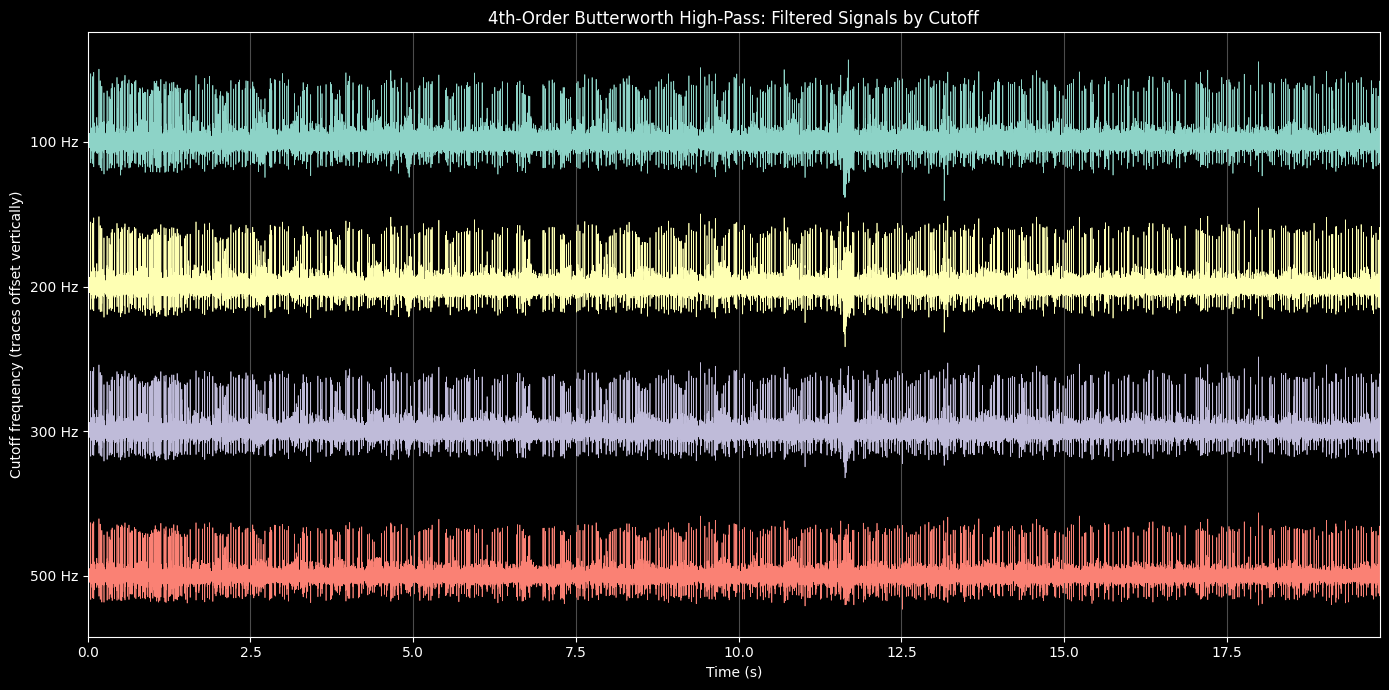

In [31]:
from scipy.signal import butter, sosfiltfilt

order = 4
cutoffs = [100, 200, 300, 500]       # Hz

# --- Design each filter and apply it (zero-phase) ---
filtered = {}
for fc in cutoffs:
    sos = butter(order, fc, btype="highpass", fs=fs, output="sos")
    filtered[fc] = sosfiltfilt(sos, x)

# --- One graph, all filtered signals, stacked with vertical offsets ---
t_start, t_end = t[0], t[-1]         # set a narrower window (e.g., 2, 3) to zoom in
mask = (t >= t_start) & (t <= t_end)

offset = 1.5 * np.ptp(filtered[cutoffs[-1]][mask])   # spacing between traces

fig, ax = plt.subplots(figsize=(14, 7))
yticks, ylabels = [], []
for i, fc in enumerate(cutoffs):
    shift = -i * offset
    ax.plot(t[mask], filtered[fc][mask] + shift, linewidth=0.5, label=f"{fc} Hz")
    yticks.append(shift)
    ylabels.append(f"{fc} Hz")

ax.set_yticks(yticks)
ax.set_yticklabels(ylabels)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Cutoff frequency (traces offset vertically)")
ax.set_title(f"{order}th-Order Butterworth High-Pass: Filtered Signals by Cutoff")
ax.set_xlim(t_start, t_end)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p2_filter_comparison.png", dpi=200)
plt.show()

Above is the raw signal filtered through four different 4th-oder high-pass Butterworth filters.
What is seen:
* It's hard to distinguish action potentials at this scale.
* There is a large amount of noise seen at around 11.5 seconds. In the recording, it sounds like the sensor was moved.
* The aforementioned noise is almost entirely filtered out using the 4th-order high-pass Butterworth filter with a cutoff frequency of 500 Hz.

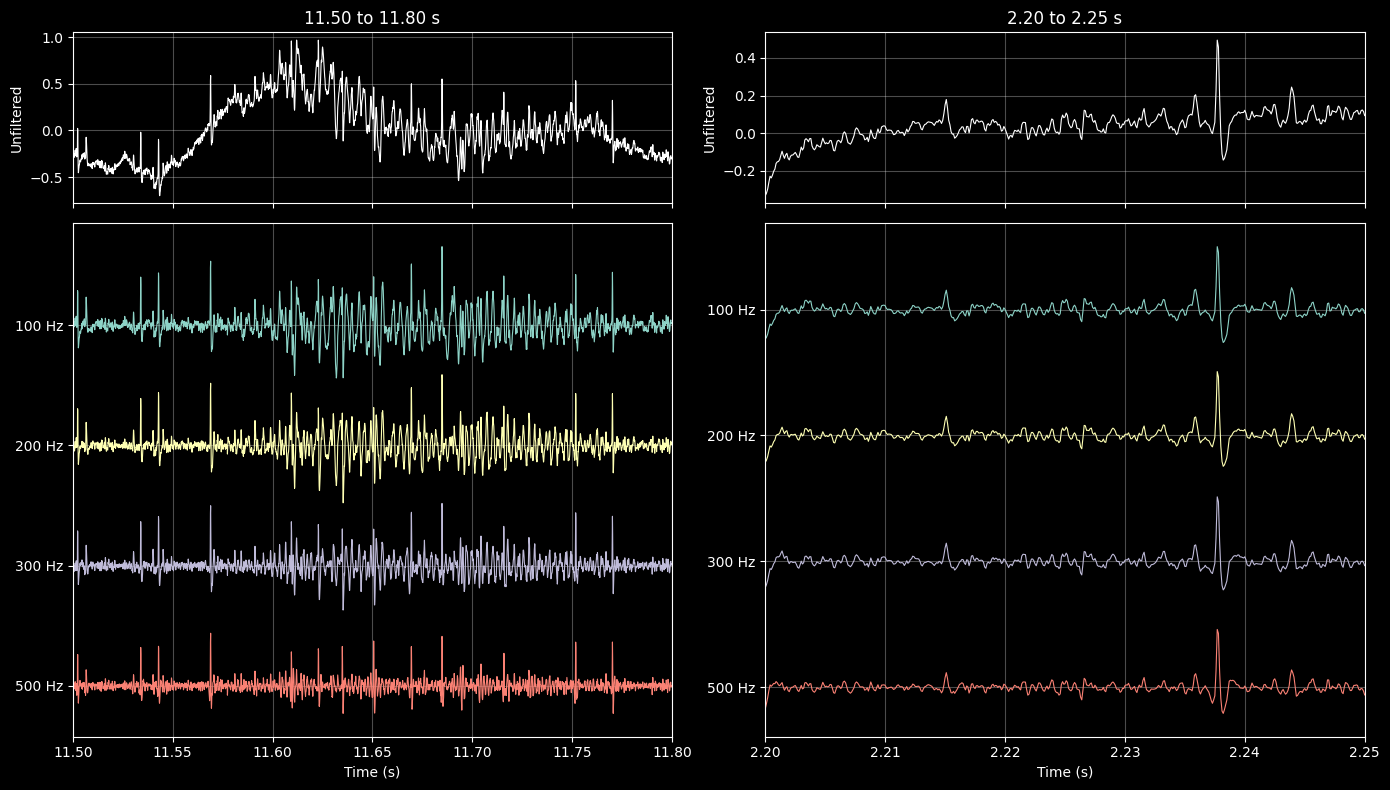

In [32]:
# --- Zoomed comparison with the unfiltered signal on top ---
windows = [(11.5, 11.8), (2.2, 2.25)]    # seconds; adjust to taste

fig, axes = plt.subplots(
    2, len(windows), figsize=(14, 8),
    sharex="col", gridspec_kw={"height_ratios": [1, 3]}
)

for col, (t0, t1) in enumerate(windows):
    m = (t >= t0) & (t <= t1)
    ax_raw, ax_filt = axes[0, col], axes[1, col]

    # Top: unfiltered signal, with its own y-axis
    ax_raw.plot(t[m], x[m], color="w", linewidth=0.8)
    ax_raw.set_title(f"{t0:.2f} to {t1:.2f} s")
    ax_raw.set_ylabel("Unfiltered")
    ax_raw.grid(True, alpha=0.3)

    # Bottom: filtered traces, offset vertically
    off = 1.5 * np.ptp(filtered[cutoffs[-1]][m])
    yticks, ylabels = [], []
    for i, fc in enumerate(cutoffs):
        shift = -i * off
        ax_filt.plot(t[m], filtered[fc][m] + shift, linewidth=0.8)
        yticks.append(shift)
        ylabels.append(f"{fc} Hz")
    ax_filt.set_yticks(yticks)
    ax_filt.set_yticklabels(ylabels)
    ax_filt.set_xlim(t0, t1)
    ax_filt.set_xlabel("Time (s)")
    ax_filt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("p2_filter_zoom_with_raw.png", dpi=200)
plt.show()

The above graphs show that the low frequency trend has been eliminated and that the 4th-order high-pass Butterworth filter with a cutoff frequency of 500 Hz really has eliminated most of the injected noise.

Since this assignment is using a threshold detector, it's best to make sure the chosen filter provides an acceptable threshold. An acceptable threshold value would be one that cleanly separates the noise from the action potentials.
To solve for this, maxima histograms will be generated. The ideal filter will produce two humps: one for the noise and one for the action potentials.

100 Hz: 36418 maxima
200 Hz: 36436 maxima
300 Hz: 36619 maxima
500 Hz: 37485 maxima


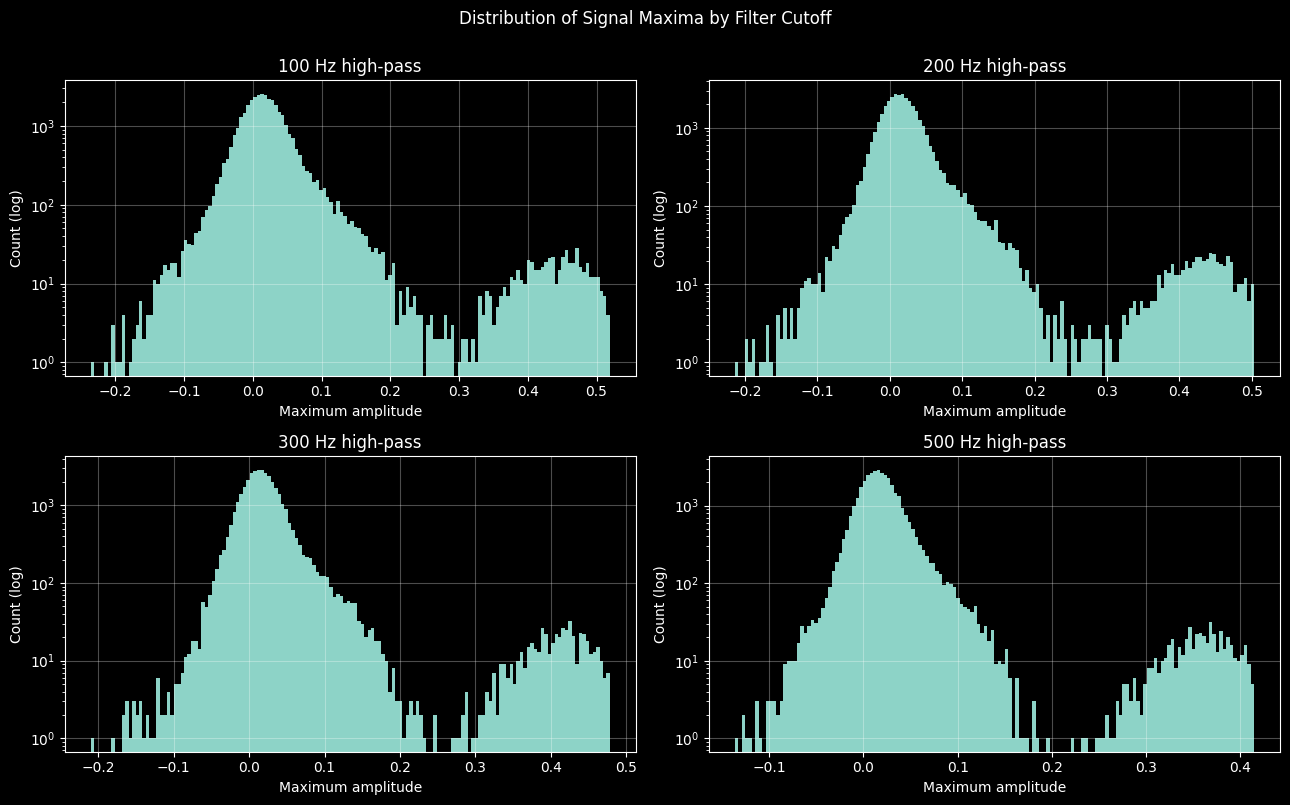

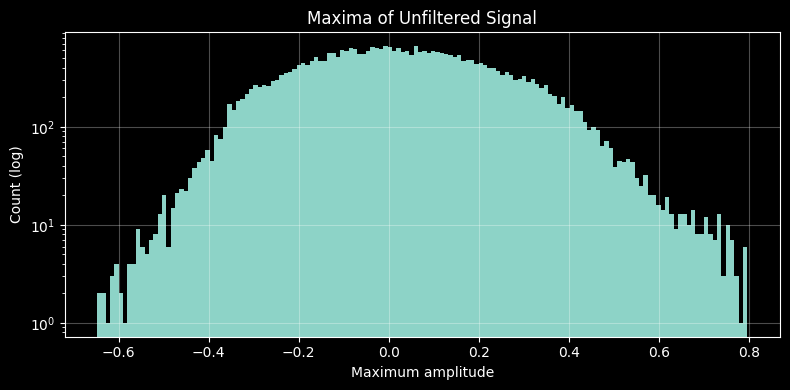

In [33]:
from scipy.signal import find_peaks

def get_maxima(sig):
    """Values of all local maxima (samples larger than both neighbors)."""
    idx, _ = find_peaks(sig)
    return sig[idx]

# --- Maxima for each signal ---
maxima_raw = get_maxima(x)
maxima_filt = {fc: get_maxima(filtered[fc]) for fc in cutoffs}

for fc in cutoffs:
    print(f"{fc} Hz: {len(maxima_filt[fc])} maxima")

# --- Histograms of filtered maxima, one panel per cutoff ---
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, fc in zip(axes.ravel(), cutoffs):
    m = maxima_filt[fc]
    hi = np.percentile(m, 99.9)          # clip the axis so one artifact doesn't squash the plot
    ax.hist(m, bins=150, range=(m.min(), hi), color="C0")
    ax.set_yscale("log")                 # log counts make a small second mode visible
    ax.set_title(f"{fc} Hz high-pass")
    ax.set_xlabel("Maximum amplitude")
    ax.set_ylabel("Count (log)")
    ax.grid(True, alpha=0.3)

plt.suptitle("Distribution of Signal Maxima by Filter Cutoff", y=1.00)
plt.tight_layout()
plt.savefig("p2_maxima_histograms.png", dpi=200)
plt.show()

# --- Deliverable 5: histogram of maxima of the unfiltered signal ---
plt.figure(figsize=(8, 4))
hi = np.percentile(maxima_raw, 99.9)
plt.hist(maxima_raw, bins=150, range=(maxima_raw.min(), hi))
plt.yscale("log")
plt.xlabel("Maximum amplitude")
plt.ylabel("Count (log)")
plt.title("Maxima of Unfiltered Signal")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p5_unfiltered_maxima.png", dpi=200)
plt.show()

The above graphs show that the 4th-order high-pass Butterworth filter with a cutoff frequency of 500 Hz is best suited for this assignment.

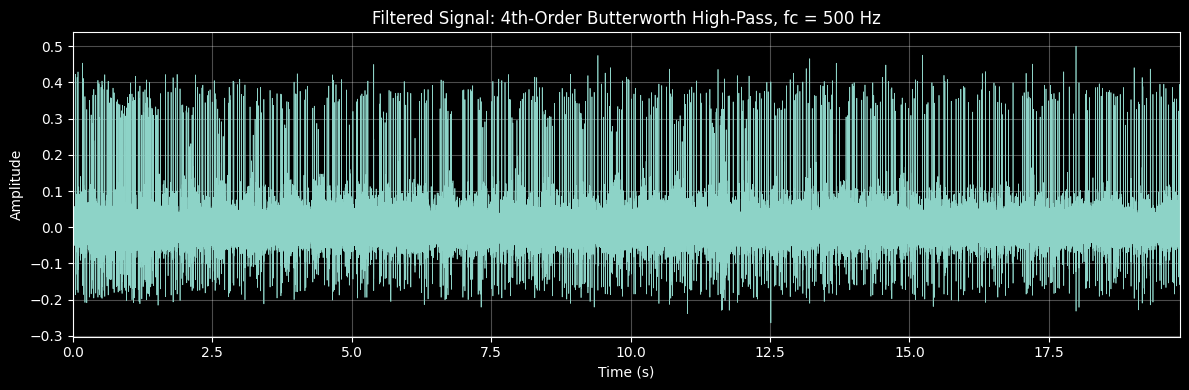

In [34]:
# --- Design and apply the 4th-order Butterworth high-pass (500 Hz) ---
order = 4
fc = 500                                              # Hz
sos = butter(order, fc, btype="highpass", fs=fs, output="sos")
y = sosfiltfilt(sos, x)                               # zero-phase filtering

# --- Deliverable 2: time-domain plot of the filtered signal ---
plt.figure(figsize=(12, 4))
plt.plot(t, y, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Filtered Signal: {order}th-Order Butterworth High-Pass, fc = {fc} Hz")
plt.xlim(t[0], t[-1])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p2_filtered_signal.png", dpi=200)
plt.show()

### Problem 3: Plot of the impulse response of your filter

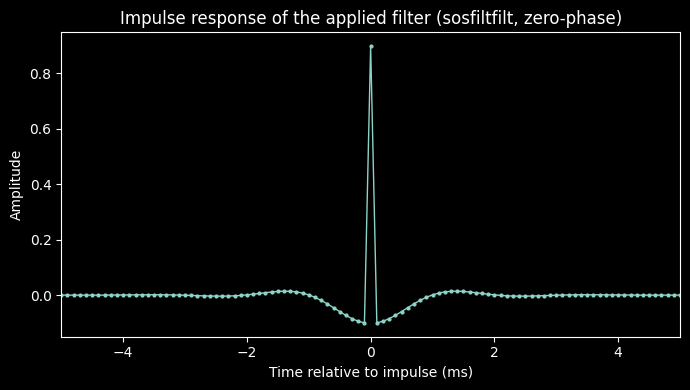

In [43]:
from scipy.signal import sosfilt, sosfiltfilt

# ---------- Deliverable 3: impulse response of the filter ----------
# Put a unit impulse in the middle of a long zero signal so both sides of the response are visible.
n_half = int(0.05 * fs)                    # 50 ms on each side of the impulse
imp = np.zeros(2 * n_half + 1)
imp[n_half] = 1.0

h_ff = sosfiltfilt(sos, imp)               # what you actually applied (forward-backward)

t_imp = (np.arange(len(imp)) - n_half) / fs * 1000   # ms, impulse at t = 0

fig, axes = plt.subplots(1, 1, figsize=(7, 4), sharex=True)
axes.set_xlim(-5, 5)
axes.plot(t_imp, h_ff, ".-", markersize=4, linewidth=1)   # show individual samples
axes.set_title("Impulse response of the applied filter (sosfiltfilt, zero-phase)")
axes.set_ylabel("Amplitude")
axes.set_xlabel("Time relative to impulse (ms)")

plt.tight_layout()
plt.savefig("p3_impulse_response.png", dpi=200)
plt.show()

### Problem 4: Time-domain plots of the first 0.2 seconds and last 0.2 seconds of the filtered signal

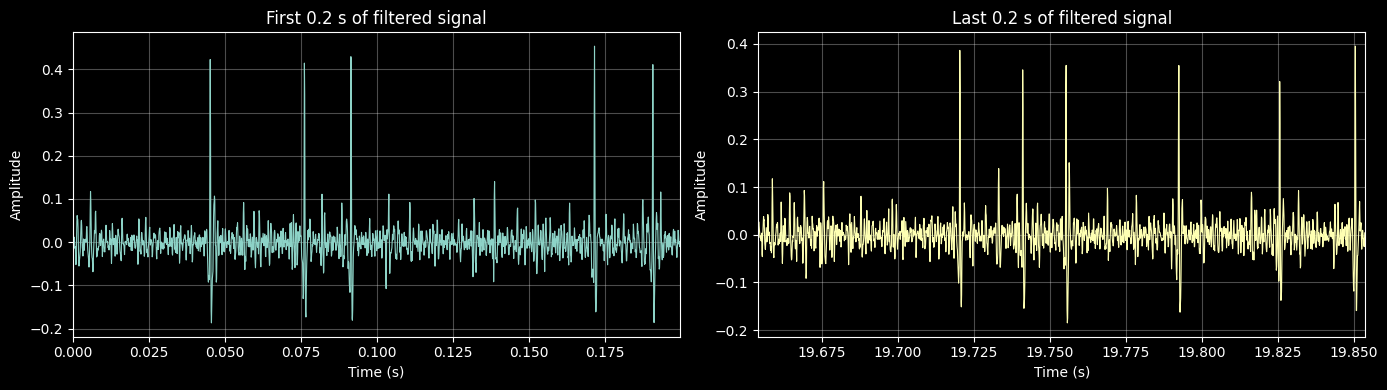

In [36]:
win = 0.2                                   # seconds
n_win = int(win * fs)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(t[:n_win], y[:n_win], linewidth=0.8)
axes[0].set_title("First 0.2 s of filtered signal")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(t[0], t[n_win - 1])
axes[0].grid(True, alpha=0.3)

axes[1].plot(t[-n_win:], y[-n_win:], linewidth=0.8, color="C1")
axes[1].set_title("Last 0.2 s of filtered signal")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlim(t[-n_win], t[-1])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("p4_first_last_0p2s.png", dpi=200)
plt.show()

Because the applied filter is a forward-backward digital filter, there are no edge effects seen.

sosfiltfilt from Scipy defaults to using "odd" signal extension: the signal is mirrored and flipped at the start and end when filter computations are conducted.

### Problems 5 and 6: Distribution (histogram) of the maxima of the unfiltered signal and distribution (histogram) of the maxima of the filtered signal

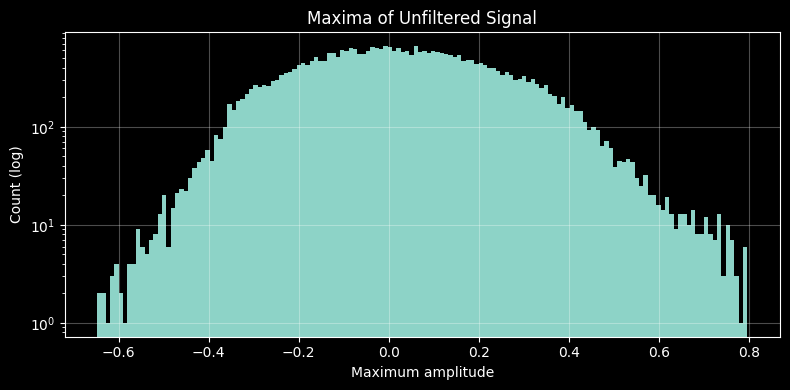

In [37]:
# --- Deliverable 5: histogram of maxima of the unfiltered signal ---
plt.figure(figsize=(8, 4))
hi = np.percentile(maxima_raw, 99.9)
plt.hist(maxima_raw, bins=150, range=(maxima_raw.min(), hi))
plt.yscale("log")
plt.xlabel("Maximum amplitude")
plt.ylabel("Count (log)")
plt.title("Maxima of Unfiltered Signal")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p5_unfiltered_maxima.png", dpi=200)
plt.show()

500 Hz: 37485 maxima


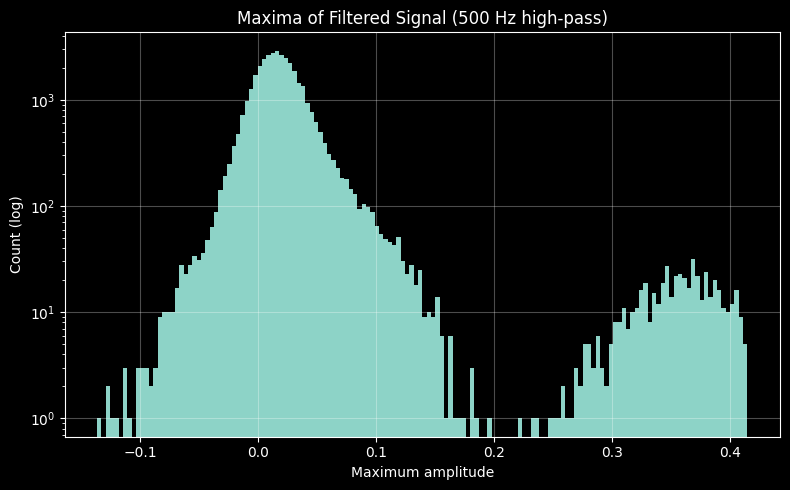

In [38]:
from scipy.signal import find_peaks

def get_maxima(sig):
    """Values of all local maxima (samples larger than both neighbors)."""
    idx, _ = find_peaks(sig)
    return sig[idx]

# --- Maxima of the 500 Hz filtered signal (y from your 500 Hz filter cell) ---
maxima_500 = get_maxima(y)
print(f"500 Hz: {len(maxima_500)} maxima")

# --- Histogram of filtered maxima ---
hi = np.percentile(maxima_500, 99.9)     # clip the axis so one outlier doesn't squash the plot

plt.figure(figsize=(8, 5))
plt.hist(maxima_500, bins=150, range=(maxima_500.min(), hi), color="C0")
plt.yscale("log")                        # log counts make a small second mode visible
plt.title("Maxima of Filtered Signal (500 Hz high-pass)")
plt.xlabel("Maximum amplitude")
plt.ylabel("Count (log)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p6_filtered_maxima.png", dpi=200)
plt.show()

### Problem 7: Why did you choose the type of filter that you applied?

* The Butterworth filter is maximally flat for all frequencies that are not attenuated. This is important as the assignment was to implement a threshold detector. I wanted the chosen filter to minimize the magnitudes of the lower frequency trend without minimizing the action potential signals.
* A 4th order was chosen for it's steep roll off.
* A band pass filter was considered, but the high-pass filter used did a good enough job. The high-pass filter was originally chosen because it was understood that the raw signal was a collection of action potentials with primarily low frequency noise added to it.
* The cutoff frequency of 500 Hz was chosen as it minimized low frequency trends, squashed movement noise, and had the cleanest maxima valley between the noise and the action potentials (see above).

### Problem 8: What are the parameters that define the filter?

* high-pass filter that attenuates frequencies below 500 Hz (the cutoff frequency).
* Butterworth design family
* 4th degree filter order
* Zero-phase (forward-backward) filtering applied using sosfiltfilt from Scipy.
* Below are the coefficients of the filter

In [39]:
print(sos)

[[ 0.66201584 -1.32403167  0.66201584  1.         -1.47967422  0.55582154]
 [ 1.         -2.          1.          1.         -1.70096433  0.78849974]]


### Problem 9: How did you tune the filter (i.e., how did you chose the parameter values for the filter)?

Several different cutoffs were tested (see Problem 2). The resulting filtered signal from the filter that had the 500 Hz cutoff frequency minimized the low frequency trend and low frequency noise. In addition, when maxima histograms were generated, the filter with the 500 Hz cutoff had the cleanest valley between the low frequency maxima and the action potential maxima. This is needed for threshold detection.

### Problem 10: Were there any edge effects caused by your filter? If so, were there edge effects at both the beginning and end of the signal? Explain.

No edge effects were visible at either end of the filtered signal (see Problem 4). The filter was applied forward and backward (using sosfiltfilt from SciPy), which means both ends of the recording are potentially vulnerable, since each pass starts from a boundary with no data beyond it. sosfiltfilt’s default odd padding extension prevents this. Before filtering, each end of the signal is extended by reflecting it about the endpoint and inverting it, which continues the local level and slope of the signal instead of introducing a sharp corner or an assumed zero. This insures that the filter has data on both sides of every sample, including those at the edges.

### Problem 11: What, if anything, did you learn from this homework?

I learned about zero-phase forward-backward digital filters and how they can be used to eliminate edge affects.

### Problem 12: What new questions, if any, do you have?

I have no questions at this time.

### AI Usage:

AI was used in the following ways:
* Code generation. All code was generated using AI. All code was checked by me.
* Graphical analysis was provided by AI to be used to make more informated decisions during the filter design process.
* Question clarifications was provided by AI.
* Filter design proposals were submitted to AI for logical checks.